# 07. A plasma etcher, wafer by wafer: are the links between sensors straight or curved?

**Why this machine.** Every plant so far (notebooks 02 to 06) ran continuously at a few steady settings, and the measure said "straight" on all of them. The few bends found came from limits and switches. A check that has never said "yes" has not shown that it can. A batch process runs through a whole recipe from start to finish, so its readings cover the stretch between stages instead of sitting in a few separate patches. That makes it the likeliest place for a "yes".

**The machine and the data.** A LAM 9600 plasma etcher at Texas Instruments, etching the metal layer off silicon wafers (Wise, Gallagher, Butler, White and Barna, *Journal of Chemometrics* 13, 379–396, 1999; data from Eigenvector Research). Each wafer is one batch. It takes about 100 seconds, with one reading a second from 19 sensors on the machine: gas flows, chamber pressure, power settings and the units that match the power to the plasma. There are 108 normal wafers and 21 wafers with a fault made on purpose, from three experiments run weeks apart (February, March and April 1996).

**Words used here.**

- **Batch**: one run of the recipe from start to end. Here, one wafer.
- **Stage**: where in the recipe a reading was taken. The file holds two recipe steps: **step 4**, the main etch of the aluminium layer, and **step 5**, the over-etch of the layers below. The stage plays the part that the operating mode played in notebook 06.
- **Straight share**: how much of a sensor's movement a straight-line model can predict from the other sensors, on wafers the model never saw. 1 means all of it.
- **Curved share**: how much *more* a flexible model predicts on the same unseen wafers, in *points* (hundredths of the 0-to-1 scale).
- **Range**: every number comes with a 90% range, found by redoing the sum many times with the wafers drawn at random (with repeats).
- **Catch rate at 1 false alarm in 100**: the share of faulty readings a detector flags, when its alarm line is set so that 1 normal reading in 100 crosses it.

**Rules fixed before the data was read** (from the task):

1. The wafer is the unit. Whole wafers are held out in five rounds; ranges come from resampling wafers.
2. Only the machine's own online readings are used: no time, wafer names, step numbers, fault flags, and no column that never moves in normal wafers.
3. The recipe step is the stage.
4. Measures as in notebooks 05 and 06: the pooled, same-moment curved share (the headline); the same with the step told to the straight model; inside each step; lags as support; and the share of each sensor's movement that lies between the steps.
5. **The "yes" rule**: the headline's whole 90% range above +3 points. If it clears +3 points but falls below +1 point once the step is told, it is reported as step-to-step level shifts, not curves.
6. The outlier rule, run by wafer.
7. The three experiments differ in level, so every hold-out round keeps all three in the fitted set. For detectors, the main alarm line is set per experiment on normal wafers of that experiment not used for fitting; one line for all three is the second version.
8. Every sensor gaining over 10 points from curves is plotted against its best single predictor, coloured by step, and labelled as a smooth curve, a corner or ceiling, separate clusters, or a two-state flip.

**Layout.** 1 the file; 2 the columns kept; 3 what was found in the file; 4 which wafers are fitted on and which held out; 5 the outlier check; 6 the headline measure; 7 sensor by sensor; 8 how much movement lies between the steps; 9 inside each step; 10 is it the experiments, or the phase of the wafer? (added after seeing the results); 11 the sensors that gain most from curves; 12 the faulty wafers; 13 detectors; 14 which detector is ahead; 15 kinds of fault; 16 summary.

## 1. The file

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
import pandas as pd

from adlab import batch, etch, explore, plots, run

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", explore.tidy)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)

etch.download()          # about 2 MB the first time; nothing if already there
print(etch.information())
etch.wafer_table()

This data set consists of the engineering variables from a
LAM 9600 Metal Etcher over the course of etching 129 wafers.
The data consists of 108 normal wafers taken during 3
experiments (numbers 29, 31 and 33) and 21 wafers with
intentionally induced faults taken during the same experiments.
Note that the experiments were run several weeks apart and data
from different experiments has a different mean and somewhat
different covariance structure. The experiment number is in the
name of the wafer in the calib_names and test_names fields,
respectively.

For more information about this data set, please see:
B.M. Wise, N.B. Gallagher, S.W. Butler, D.D. White, Jr. and
G.G. Barna, "A Comparison of Principal Components Analysis,
Multi-way Principal Components Analysis, Tri-linear
Decomposition and Parallel Factor Analysis for Fault Detection
in a Semiconductor Etch Process", J. Chemometrics, in press,
1999

The specific fields in this structure array are described
below:

  INFORMATION: [ 29x6

,normal wafers in the file,normal wafers used,faulty wafers,"readings per wafer, fewest","readings per wafer, middle","readings per wafer, most"
experiment 29,34,34,9,93,102,112
experiment 31,37,36,6,3,100,108
experiment 33,37,37,6,95,99,108


**What this shows.** The file's own description, then the wafers per experiment. Only `MACHINE_Data.mat` was downloaded (about 2 MB). The two other files on the page (light from the plasma, and a radio-frequency monitor) were not, as the task says. The data sits in `data/raw/metal_etch/` and is not committed.

The file's description says nothing about whether the faults last the whole wafer. Section 12 answers that from a public paper by the same authors and from the data.

## 2. The columns kept

*Listed before anything was computed.* The file has 21 columns. Time and the step number are left out as sensors (the step number is kept aside as the stage). The other 19 all move in the normal wafers, so all 19 are kept.

In [2]:
etch.columns_table()

,kept,what it is,distinct values,share at commonest value,lowest,highest
column,,,,,,
Time,no,"the time of the reading, not a measurement",NaN,NaN,NaN,NaN
Step Number,no,"the recipe step: used as the stage of the batch, not as ...",NaN,NaN,NaN,NaN
BCl3 Flow,yes,Flow of boron trichloride gas into the chamber,4,0.68,750,753
Cl2 Flow,yes,Flow of chlorine gas into the chamber,9,0.523,749,757
RF Btm Pwr,yes,"Radio-frequency power to the bottom electrode, under the...",19,0.22,124,142
RF Btm Rfl Pwr,yes,Bottom radio-frequency power reflected back,2,0.989,0,1
Endpt A,yes,Endpoint signal: plasma light used to tell when the meta...,1618,0.007,288,3020
He Press,yes,"Helium pressure behind the wafer, which cools it",4,0.427,99,102
Pressure,yes,Chamber pressure,174,0.127,1138,1316


**What this shows.** All 19 sensor columns are kept. Several of them are read in coarse steps: the gas flows and the helium pressure take only 4 to 9 different values, and the two "reflected power" readings are nearly always at one value (the bottom one is 0 for 99% of readings, and 1 otherwise). A sensor like that can only flip between a few values. If one of them turns out "curved", section 11 will show whether it is just flipping.

The meanings in the "what it is" column are short descriptions of this kind of machine. The file itself gives only the column names, and it does not say how "RF Pwr" differs from "RF Btm Pwr".

## 3. What was found in the file before measuring

In [3]:
etch.oddities().T

,normal wafers,faulty wafers
wafers,108,21
with the first reading filed last,107,20
with two readings stamped with the same time,"l2911, l3301, l3311","l3319, l3339"
step 4 before step 5 once in time order,every wafer,every wafer
wafers under 50 readings,l3125 (3),none
wafers with under 20 readings in a step,none,l3122 (step 4: 3)


**What this shows.**

- **Rows out of order.** In 107 of the 108 normal wafers (and 20 of the 21 faulty ones) the wafer's first reading is filed as its last row. Every wafer's rows are put back in time order. After that, every wafer runs through step 4 and then step 5, as it should.
- **Two readings at the same time.** Five wafers have two different readings stamped with the same time, at the very start. Both are kept, in the order the file gives them.
- **One wafer is a stub.** Normal wafer l3125 has 3 readings instead of about 100. It is an incomplete recording and is left out, leaving 107 normal wafers (34, 36 and 37 per experiment).
- **One faulty wafer is short.** Wafer l3122 (an RF +8 fault) has only 3 readings in step 4. It is kept; most of its readings are from step 5.

## 4. Which wafers are fitted on, and which are held out

*This section was written before any curved share was computed or any detector was run.*

**For the curved share.** The 107 normal wafers, in the order the file gives them (experiment 29, 31, 33; wafer numbers rising), are dealt to five rounds like cards: 1, 2, 3, 4, 5, 1, 2, ... In each round, the wafers dealt to that round are held out whole and the models are fitted on all the others. So:

- no wafer is ever both fitted on and scored in the same round, and each is scored exactly once;
- every round fits on about four fifths of every experiment and holds out about a fifth of every experiment, spread over that experiment's whole time (rule 7);
- the ranges come from drawing the 107 wafers at random with repeats, 500 times.

**Versions beside the headline.** *Step told*: the straight model gets its own level in each step. *Lags*: the models also see the other sensors' readings 1, 2, 5 and 10 seconds earlier, inside the same wafer (the same numbers of readings back as on the chemical plant). *Inside each step*: the same rounds, using only the readings from one step.

**For the detectors.** Inside each experiment, the normal wafers in order are given roles in turn: fit, fit, fit, line, check, fit, fit, fit, line, check, ...

- **fit** (66 wafers): the detectors are fitted on these, all three experiments together;
- **line** (21 wafers, 7 per experiment): these set the alarm line, separately for each experiment (the main version) or together (the second version);
- **check** (20 wafers): only scored. They show whether the alarm line carries over to normal wafers it was not set on: about 1 false alarm in 100 if it does.

The 21 faulty wafers are all scored. No wafer a detector was fitted on is ever scored.

In [4]:
etch.split_table()

,experiment 29: held out,experiment 29: fitted on,experiment 31: held out,experiment 31: fitted on,experiment 33: held out,experiment 33: fitted on
round 1,7,27,7,29,8,29
round 2,7,27,7,29,8,29
round 3,7,27,7,29,7,30
round 4,7,27,7,29,7,30
round 5,6,28,8,28,7,30


In [5]:
etch.role_table()

,fitted on,set the alarm line,only scored (false-alarm check)
experiment 29,21,7,6
experiment 31,22,7,7
experiment 33,23,7,7


**What this shows.** The first table: the five rounds for the curved share, with every experiment on both sides in every round. The second: the detector roles per experiment.

## 5. Does one wafer dominate? (the outlier rule)

The rule: if a single wafer holds more than half of any sensor's movement, results are reported with and without it, and the version without it is the headline. With 107 wafers an even share is about 0.009.

In [6]:
movement, flagged = etch.outlier_check()
print("Wafers holding more than half of any sensor's movement:", flagged or "none")
movement.head(6)

Wafers holding more than half of any sensor's movement: none


,largest share,run,even share
sensor,,,
RF Btm Rfl Pwr,0.072,l3140,0.009
TCP Rfl Pwr,0.043,l3331,0.009
RF Tuner,0.033,l3301,0.009
RF Pwr,0.025,l2904,0.009
Endpt A,0.018,l3108,0.009
RF Impedance,0.018,l3326,0.009


**What this shows.** The largest share held by one wafer is about 0.07 (the bottom reflected power, which is almost always 0, so the few wafers where it reads 1 hold most of its movement). No wafer comes near one half. **The rule is not triggered**: all 107 wafers are used, and there is one version of each result.

## 6. The headline measure, and the versions beside it

The first row is the headline: all 107 wafers pooled, both steps, each sensor predicted from the other 18 at the same moment. The rows below are the versions listed in section 4. The first time, this cell takes about 8 minutes; after that the answers are read from `results/cache`.

In [7]:
pooled = etch.measures()
batch.measure_table(pooled)

,straight share,"straight, low","straight, high","curved share, points","curved low, points","curved high, points",sensors gaining over 5 points,sensors gaining over 10 points,held-out batches,held-out readings
measure,,,,,,,,,,
same moment (the headline),0.367,0.361,0.372,8.147,7.888,8.371,12,7,107,10767
"same moment, stage told to the straight model",0.384,0.378,0.389,7.229,6.988,7.448,12,6,107,10767
+ 1 back,0.392,0.387,0.397,6.306,6.103,6.512,9,6,107,10660
"+ 1, 2 back",0.403,0.398,0.408,5.432,5.24,5.62,8,6,107,10553
"+ 1, 2, 5 back",0.414,0.409,0.419,4.429,4.223,4.623,8,1,107,10232
"+ 1, 2, 5, 10 back",0.417,0.413,0.422,3.054,2.912,3.206,7,0,107,9697


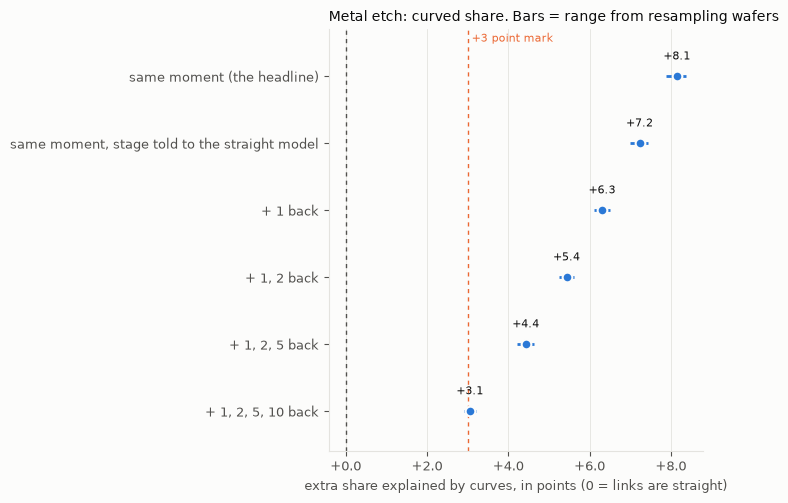

In [8]:
plots.curved_share(pooled, title="Metal etch: curved share. Bars = range from resampling wafers", mark=0.03, points=True);

**What this shows.**

- **The headline: curved share +8.1 points, range +7.9 to +8.4.** The whole range lies **above +3 points**. This is the first dataset in the project where it does. The straight share is 0.37 (0.36 to 0.37). Seven sensors gain more than 10 points from curves, and twelve gain more than 5.
- **Step told to the straight model: +7.2 points (+7.0 to +7.4).** Giving each step its own level takes away less than 1 point. Under rule 5 this is **not** a step-to-step level shift: it stays far above +1 point.
- **Lags:** +6.3, +5.4, +4.4 and +3.1 points (the last range +2.9 to +3.2) as 1, 2, 5 and 10 seconds of the other sensors' history are added. The straight share rises a little (0.39 to 0.42). Part of what the flexible model finds at the same moment is the sensors' recent history, which the straight model can use too once it is offered. Supporting numbers only.

In the plot, the dashed orange line marks +3 points.

## 7. Sensor by sensor

The headline measure one sensor at a time, most curved first (shares on the 0-to-1 scale: 0.10 is 10 points). The last two columns repeat it with the step told.

In [9]:
by_sensor = etch.sensor_table(pooled[batch.SAME_MOMENT])
told = etch.sensor_table(pooled[batch.TOLD])
curved = batch.most_curved(pooled[batch.SAME_MOMENT])
print("Sensors gaining over 10 points from curves:", ", ".join(curved) or "none")
pd.concat([by_sensor, told[["straight", "curved"]].add_suffix(", step told")], axis=1)

Sensors gaining over 10 points from curves: Endpt A, Vat Valve, RF Pwr, Pressure, TCP Impedance, RF Phase Err, RF Impedance


,what it measures,straight,curved,curved_low,curved_high,"straight, step told","curved, step told"
sensor,,,,,,,
Endpt A,Endpoint signal: plasma light used to tell when the meta...,0.707,0.199,0.192,0.207,0.755,0.169
Vat Valve,Position of the valve that holds the chamber pressure,0.548,0.194,0.182,0.206,0.742,0.082
RF Pwr,A second radio-frequency power reading (the file does no...,0.681,0.181,0.169,0.195,0.703,0.163
Pressure,Chamber pressure,0.729,0.149,0.144,0.155,0.729,0.151
TCP Impedance,Top coil's matching unit: impedance,0.143,0.145,0.129,0.159,0.145,0.146
RF Phase Err,Bottom power's matching unit: phase error,0.463,0.119,0.113,0.126,0.463,0.12
RF Impedance,Bottom power's matching unit: impedance,0.294,0.112,0.097,0.126,0.303,0.11
TCP Phase Err,Top coil's matching unit: phase error,0.221,0.073,0.065,0.082,0.222,0.074
RF Tuner,Bottom power's matching unit: tuning setting,0.47,0.07,0.06,0.079,0.47,0.07


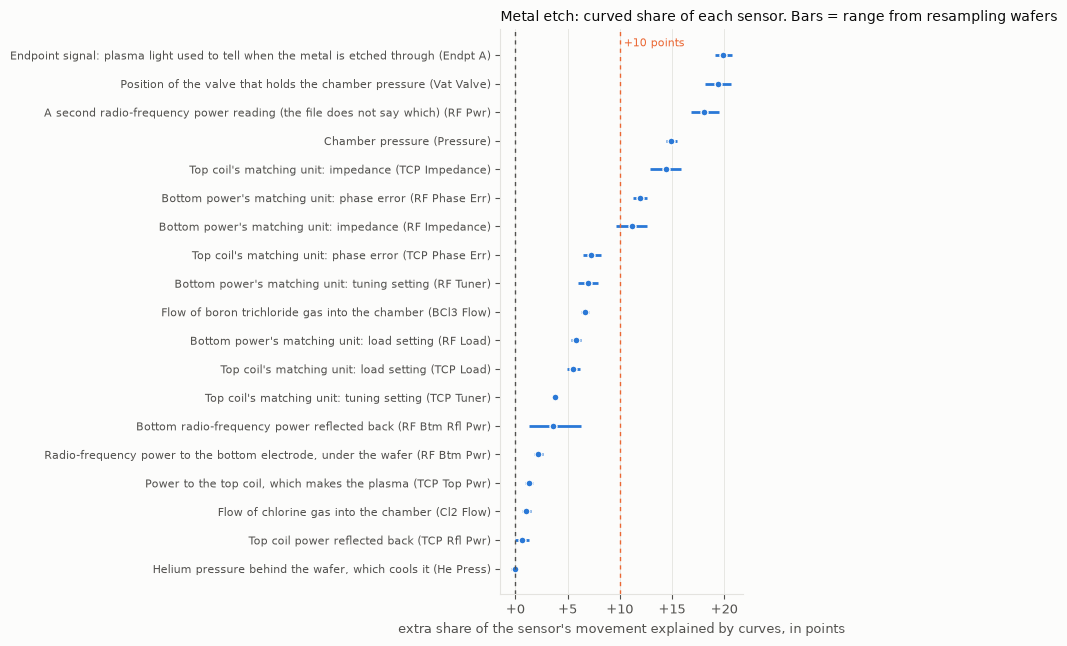

In [10]:
plots.curved_by_sensor(by_sensor, "Metal etch: curved share of each sensor. Bars = range from resampling wafers",
                       low="curved_low", high="curved_high");

**What this shows.** The seven sensors over 10 points are the endpoint signal (+20 points), the pressure valve position (+19), the second RF power reading (+18), chamber pressure (+15), the top coil's matching impedance (+14), the bottom matching unit's phase error (+12) and its impedance (+11). Telling the step barely changes them, except the valve position (+19 to +8).

Look at the straight column too. The settings the machine holds steady (helium pressure, top coil power, bottom RF power, chlorine flow) have straight shares near 0: their small wobble around the set point is noise that no other sensor predicts. That is why the average straight share (0.37) is so much lower than on the chemical plant (0.90).

## 8. How much of each sensor's movement lies between the two steps?

Notebook 06 found that when nearly all of a sensor's movement is the jump from one patch of readings to another, a straight model with enough inputs can hit every patch exactly, so the pooled measure cannot see a curve between them. This table checks whether that applies here: for each sensor, the share of its movement that is the gap between the steps' averages, and the same for the gap between the three experiments.

In [11]:
between = etch.between_table()
share = between["share between stages"]
print(f"Sensors with over 90% of their movement between the two steps: {int((share > 0.9).sum())} of {share.notna().sum()}; "
      f"over half: {int((share > 0.5).sum())}")
between

Sensors with over 90% of their movement between the two steps: 0 of 19; over half: 1


,what it measures,share between stages,share between experiments
sensor,,,
RF Btm Pwr,"Radio-frequency power to the bottom electrode, under the...",0,0.001
TCP Top Pwr,"Power to the top coil, which makes the plasma",0,0
RF Btm Rfl Pwr,Bottom radio-frequency power reflected back,0,0.001
TCP Phase Err,Top coil's matching unit: phase error,0,0
TCP Impedance,Top coil's matching unit: impedance,0.001,0.003
RF Tuner,Bottom power's matching unit: tuning setting,0.002,0.199
He Press,"Helium pressure behind the wafer, which cools it",0.003,0.001
Cl2 Flow,Flow of chlorine gas into the chamber,0.003,0.001
RF Impedance,Bottom power's matching unit: impedance,0.006,0.001


**What this shows.** **Between the steps:** for every sensor but one, less than a quarter of its movement is the gap between step 4 and step 5. Only the valve position has about half. So the two steps are not two separate islands, and the problem found in notebook 06 does not apply to the steps.

**Between the experiments** it is different. For the second RF power reading, chamber pressure and the endpoint signal, more than half the movement is the gap between the three experiments. These three are among the seven most curved sensors. So the experiments might be islands, and section 10 checks this.

## 9. Inside each step

The same measure using only the readings from one step, with the same rounds.

In [12]:
inside = etch.within_steps()
batch.measure_table(inside)

,straight share,"straight, low","straight, high","curved share, points","curved low, points","curved high, points",sensors gaining over 5 points,sensors gaining over 10 points,held-out batches,held-out readings
measure,,,,,,,,,,
step 4,0.332,0.325,0.338,8.295,7.959,8.658,11,6,107,5074
step 5,0.409,0.402,0.415,5.366,5.007,5.7,8,5,107,5693


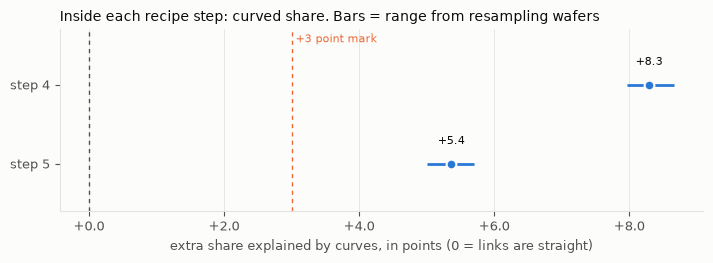

In [13]:
plots.curved_share(inside, title="Inside each recipe step: curved share. Bars = range from resampling wafers", mark=0.03, points=True);

**What this shows.** **Inside step 4: +8.3 points (+8.0 to +8.7). Inside step 5: +5.4 points (+5.0 to +5.7).** Both ranges lie above +3 points. The curvature is inside the steps, not in the jump between them.

## 10. Is it the experiments, or the phase of the wafer?

*Everything in this section was added after seeing sections 6 to 9. It was not part of the rules fixed in advance, and no rule or setting was changed because of it.*

Two possible explanations other than a curve:

- **The experiments.** They were run weeks apart and sit at different levels (section 8). A flexible model might just be recognising which experiment a wafer is from. Check: tell the straight model the experiment (its own level per experiment), or both step and experiment; and measure inside each experiment on its own.
- **The phase of the wafer.** A step is not uniform inside. Step 4 has a start-up and then the main etch, and ends when the metal is etched through (about 50 seconds in). Step 5 etches the layers below, first one and then the next. A flexible model might just be recognising where in the step a reading is. Check: tell the straight model which tenth of the step each reading is in (20 stages in all). This is the stage the task fixes for Pensim.

In [14]:
extra = etch.experiment_checks()
batch.measure_table(extra)

,straight share,"straight, low","straight, high","curved share, points","curved low, points","curved high, points",sensors gaining over 5 points,sensors gaining over 10 points,held-out batches,held-out readings
measure,,,,,,,,,,
"same moment, experiment told to the straight model",0.402,0.398,0.407,5.987,5.78,6.17,9,4,107,10767
"same moment, step and experiment told to the straight model",0.418,0.413,0.423,5.001,4.799,5.175,7,3,107,10767
"same moment, step and tenth of the step told to the straight model",0.423,0.418,0.428,4.587,4.388,4.774,8,2,107,10767
inside experiment 29,0.365,0.36,0.37,7.32,6.902,7.64,10,4,34,3486
inside experiment 31,0.37,0.364,0.375,6.676,6.3,7.006,9,5,36,3635
inside experiment 33,0.39,0.382,0.398,5.645,5.1,6.107,7,3,37,3646


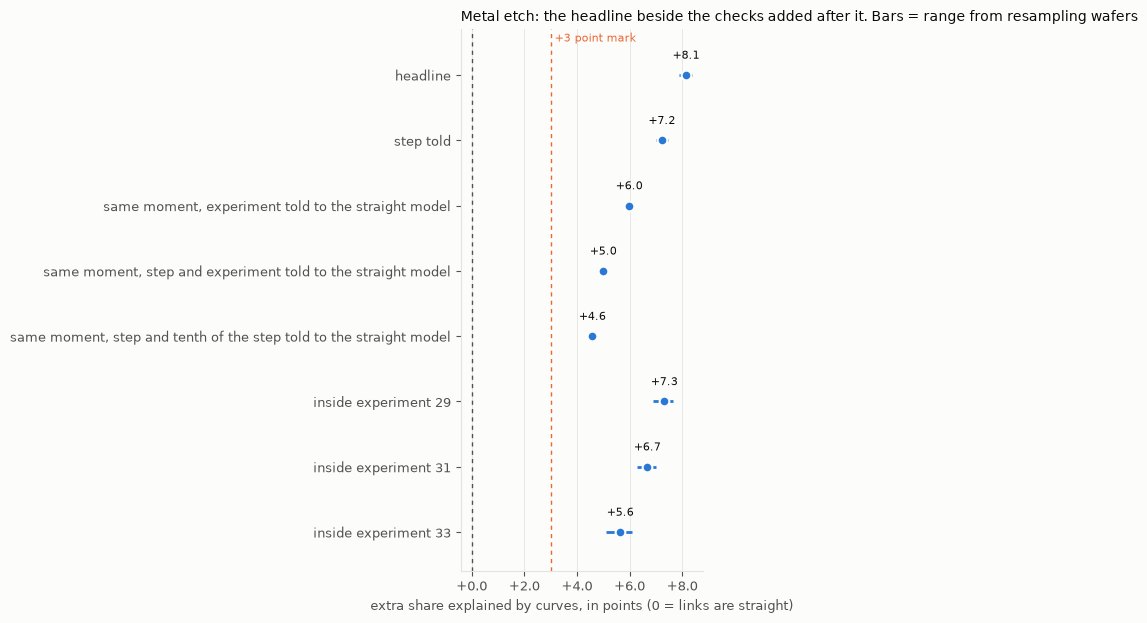

In [15]:
plots.curved_share({"headline": pooled[batch.SAME_MOMENT], "step told": pooled[batch.TOLD], **extra},
                   title="Metal etch: the headline beside the checks added after it. Bars = range from resampling wafers",
                   mark=0.03, points=True);

**What this shows.** Every one of these checks still leaves the curved share **above +3 points**, with its whole range above:

- experiment told: **+6.0** (+5.8 to +6.2);
- step and experiment told: **+5.0** (+4.8 to +5.2);
- step and tenth of the step told: **+4.6** (+4.4 to +4.8);
- inside experiment 29: **+7.3** (+6.9 to +7.6); inside 31: **+6.7** (+6.3 to +7.0); inside 33: **+5.6** (+5.1 to +6.1).

So experiment levels and the phase of the wafer explain part of the headline (from +8.1 down to between +4.6 and +6), but not all of it.

Next: *where in a wafer* the flexible model gains, for the seven most curved sensors (each row adds up to 1; the last row is the share of readings in each stretch), and four of them traced over a wafer.

,seconds 0-5,seconds 5-15,seconds 15-45,seconds 45-55,seconds 55-65,seconds 65 on
sensor,,,,,,
Endpt A,0.063,0.159,0.437,0.056,0.149,0.136
Vat Valve,0.018,0.187,0.321,0.044,0.044,0.386
RF Pwr,0.074,0.204,0.198,0.083,0.143,0.297
Pressure,0.383,0.261,0.104,0.126,0.088,0.039
TCP Impedance,0.161,0.569,0.112,0.032,0.053,0.073
RF Phase Err,0.023,0.242,0.26,0.176,0.185,0.113
RF Impedance,0.037,0.158,0.171,0.12,0.13,0.384
share of all readings,0.05,0.099,0.298,0.099,0.099,0.354


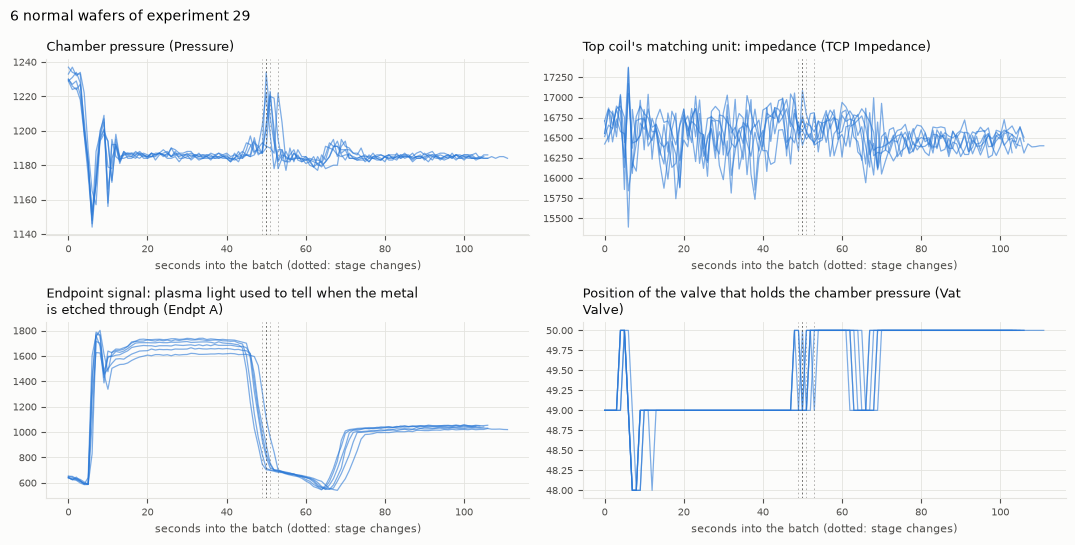

In [16]:
display(etch.gain_by_position(curved))
etch.over_a_wafer(["Pressure", "TCP Impedance", "Endpt A", "Vat Valve"]);

**What this shows.**

- **Chamber pressure and the top coil's matching impedance** gain mostly in the **first 15 seconds** of a wafer: 64% and 73% of their gain, from 15% of the readings. The traces show why. Pressure sits flat at about 1185 for most of the wafer, but swings sharply as the plasma starts, spikes again at the step change (about 50 s, just after the metal is etched through), and wobbles once more at about 65 s, when the next layer is etched through. These short swings are where the flexible model beats the straight one. Once the straight model is told the tenth of the step, pressure's gain falls from 15 to 7 points.
- **The endpoint signal** gains mostly in seconds 15 to 45, the main etch, where it sits on a plateau whose height differs from wafer to wafer and from experiment to experiment.
- **The valve position, the second RF power reading and the bottom matching unit's impedance** gain fairly evenly through the wafer.

## 11. The sensors that gain most from curves

Every sensor that gains more than 10 points from curves in the headline measure, plotted against the one other sensor that on its own says most about it, each reading coloured by step (rule 8). Before the plot, numbers that help name the shape: how many different values the sensor takes, how often it sits at one value or at its lowest or highest, and how much of its movement lies between the steps. In the plots, a reading that takes 20 or fewer different values (a whole-number reading, the 4-position valve) is spread a little sideways around each value, so that dots sitting on the same value can be seen; the spread is less than half the gap between values.

,what it measures,best single predictor,share explained,which measures
sensor,,,,
Endpt A,Endpoint signal: plasma light used to tell when the meta...,Vat Valve,0.618,Position of the valve that holds the chamber pressure
Vat Valve,Position of the valve that holds the chamber pressure,Endpt A,0.46,Endpoint signal: plasma light used to tell when the meta...
RF Pwr,A second radio-frequency power reading (the file does no...,Vat Valve,0.716,Position of the valve that holds the chamber pressure
Pressure,Chamber pressure,RF Pwr,0.627,A second radio-frequency power reading (the file does no...
TCP Impedance,Top coil's matching unit: impedance,TCP Phase Err,0.084,Top coil's matching unit: phase error
RF Phase Err,Bottom power's matching unit: phase error,Endpt A,0.386,Endpoint signal: plasma light used to tell when the meta...
RF Impedance,Bottom power's matching unit: impedance,RF Pwr,0.237,A second radio-frequency power reading (the file does no...


,distinct values,share at commonest value,share at its lowest,share at its highest,share between stages
sensor,,,,,
Endpt A,1618,0.007,0,0,0.201
Vat Valve,4,0.406,0.01,0.235,0.54
RF Pwr,15,0.171,0,0,0.071
Pressure,174,0.127,0,0,0.006
TCP Impedance,765,0.006,0,0,0.001
RF Phase Err,3596,0.001,0,0,0.242
RF Impedance,1422,0.002,0,0,0.006


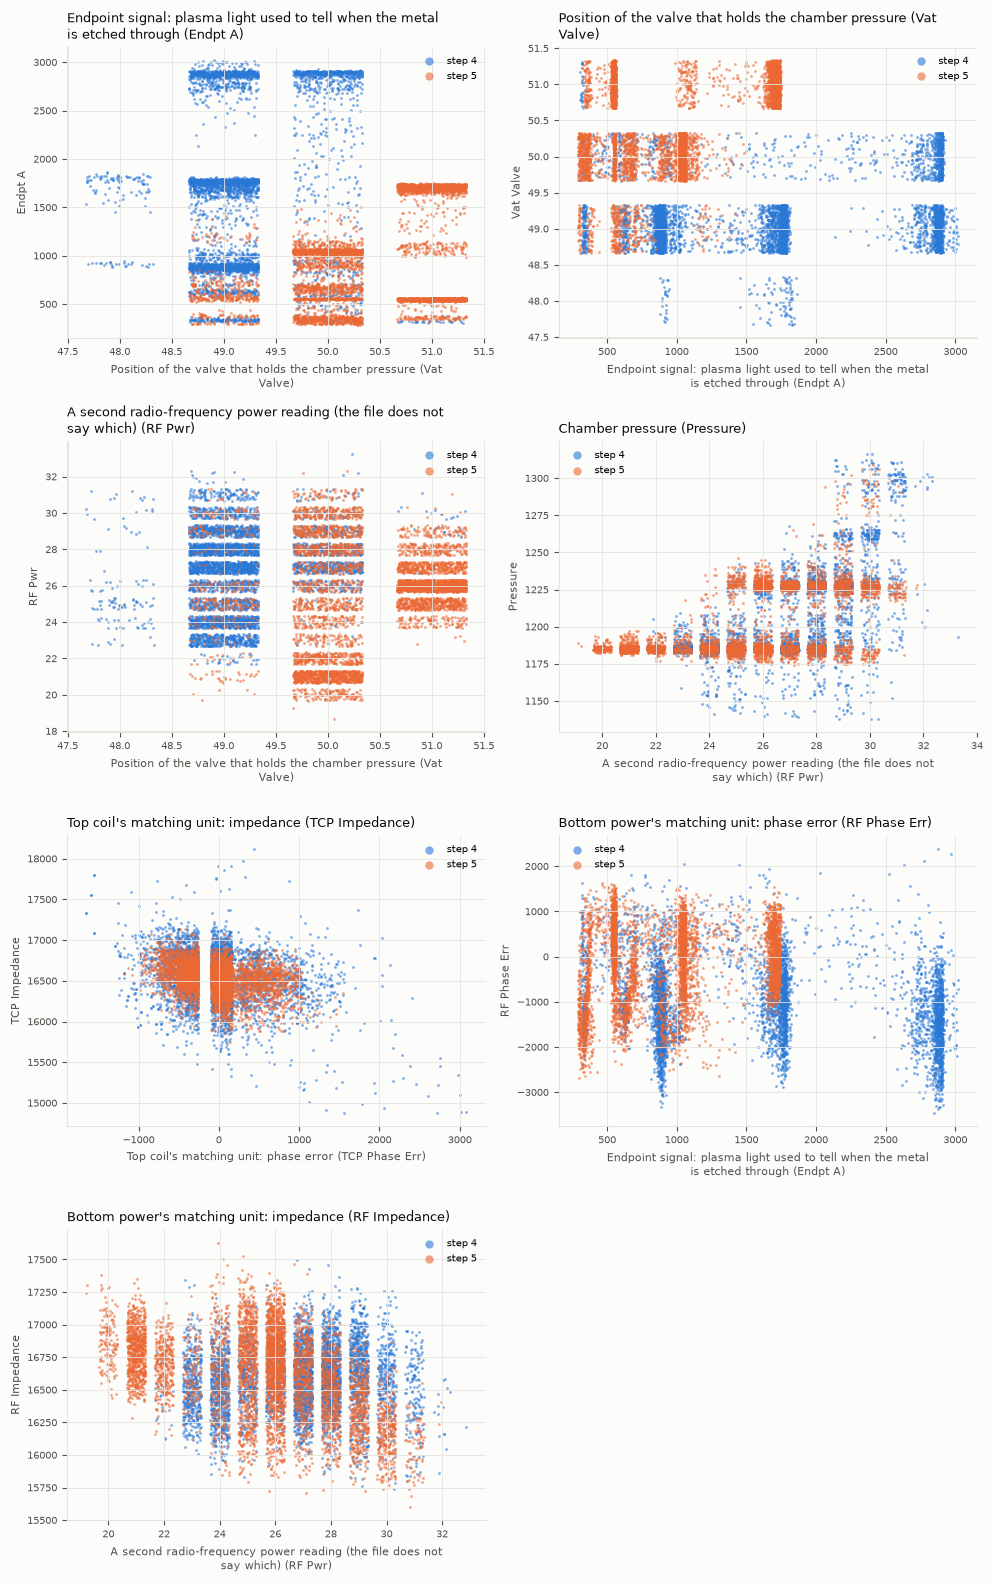

In [17]:
display(etch.best_partner(curved))
display(etch.shape_clues(curved))
etch.curved_scatter(curved);

*Added after seeing the plot above:* the same pairs, coloured by experiment instead of step.

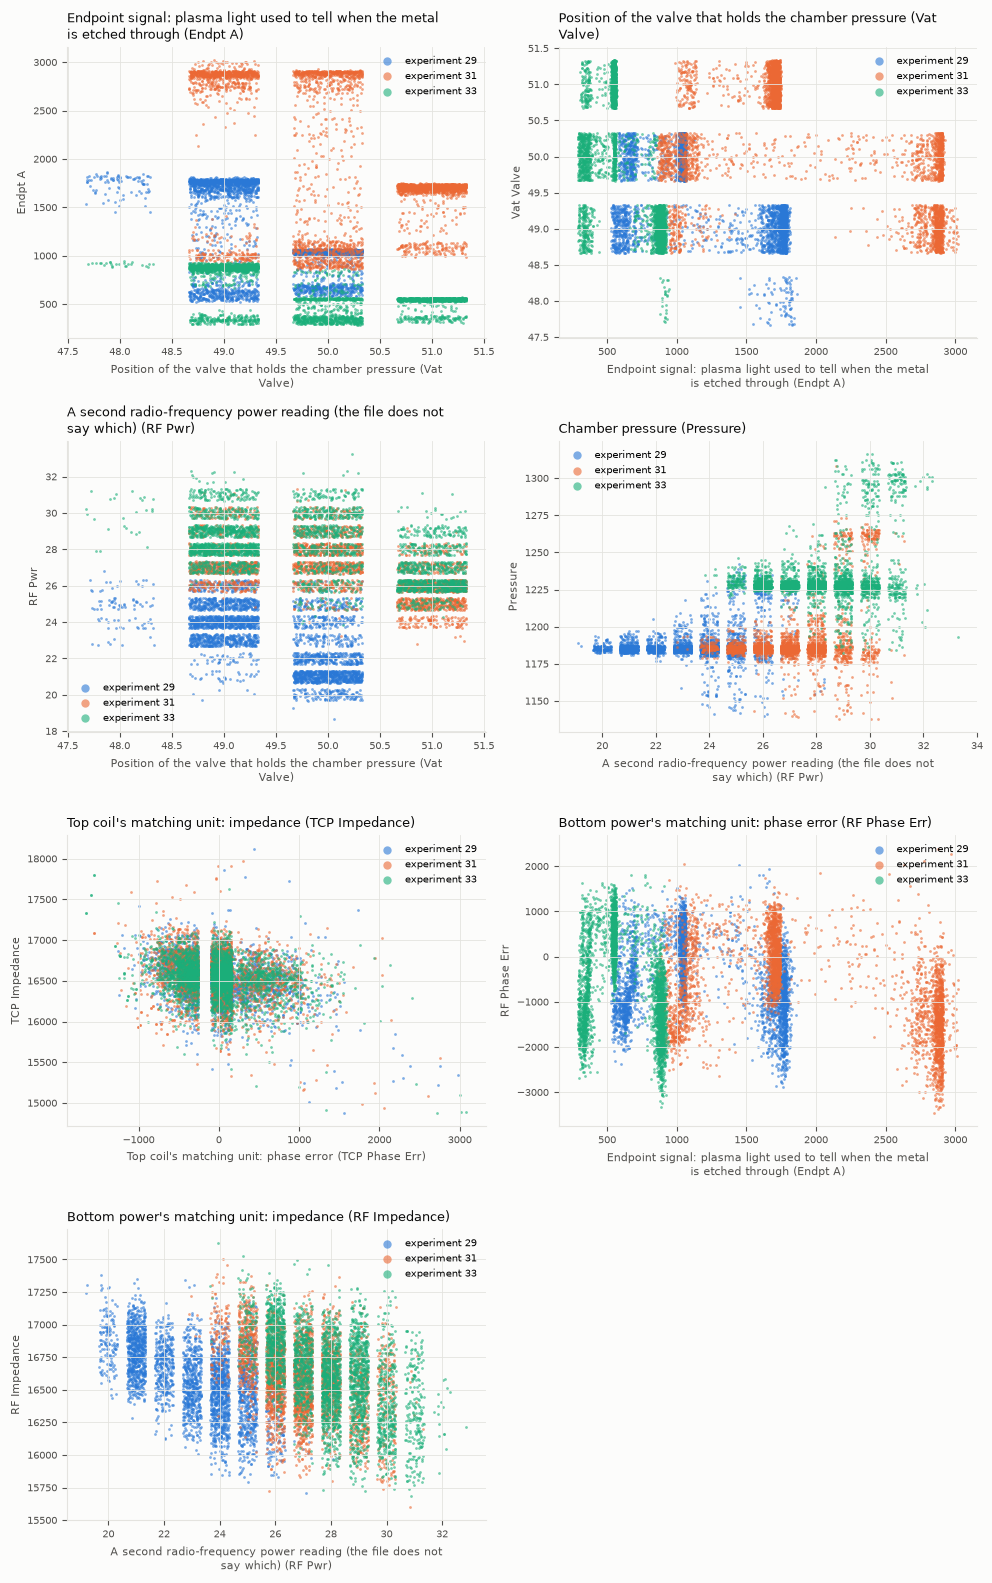

In [18]:
etch.scatter_by_experiment(curved);

**What this shows.** Several of the best single partners are readings taken in whole numbers (the valve position takes 4 values, the second RF power reading 15), so many panels are stripes rather than clouds. Even so, the two colourings show what each shape is. Labels (rule 8), as I read the plots and the tables above:

| Sensor | Gain | Label | Why |
| --- | --- | --- | --- |
| Endpoint signal | +20 | **separate clusters** | flat bands: it sits on plateaus (before and after the metal is etched through) at a different height in each experiment |
| Pressure valve position | +19 | **two-state flip** | it takes only 4 values and steps between neighbouring ones; telling the step halves its gain |
| Second RF power reading | +18 | **two-state flip** | a whole-number reading that flips between neighbouring values, at a different level in each experiment |
| Chamber pressure | +15 | **separate clusters** | two flat levels (about 1185 and 1225, depending on the experiment), with the short swings at start-up and at the step change as a spray of their own around them |
| Top coil matching impedance | +14 | **separate clusters** | mostly the start-up swing; against its best partner there is no shape at all (that partner explains only 8%) |
| Bottom matching phase error | +12 | **separate clusters** | one vertical band per plateau of the endpoint signal and per experiment |
| Bottom matching impedance | +11 | **separate clusters** | it falls gently as the second RF power reading rises, but the step-5 readings at low power (20 to 22) sit as their own patch above that slope |

**None is a smooth curve**, and none is clearly a corner or a ceiling. The gain comes from separate patches (phases of the wafer, experiments, start-up swings) and from coarse readings flipping between values. Section 10 shows these patches are not just level shifts a straight model could absorb if told the step, the experiment or the tenth of the step. Inside each patch the sensors still relate in ways a straight line does not capture.

## 12. The faulty wafers: does a fault last the whole wafer?

**From the authors.** A public paper by the same group on the same experiments (Wise, Gallagher, Butler, White and Barna, "A comparison of principal component analysis, multiway principal component analysis, trilinear decomposition and parallel factor analysis for fault detection in a semiconductor etch process", available as [Sensitivity.pdf](http://www.eigenvector.com/Docs/Sensitivity.pdf) on the Eigenvector site) says:

- each faulty wafer was etched with one setting moved off the normal recipe (top coil power, radio-frequency power, pressure, chlorine or BCl3 flow, or helium chuck pressure), so the fault is there for the whole wafer;
- **in the file, the setting that was moved was then shifted back by a constant so that its average looks normal.** For example, a top coil power fault of +50 watts shows the top coil power at its usual value. This makes the fault look like a sensor reading that is off by a constant: the machine thinks it is at the right setting and is not. The fault can only be seen in how the *other* sensors respond.

**From the data.** The table cuts each step of each faulty wafer into thirds. For each third it counts the sensors whose average is more than 3 spreads from the same third of normal wafers of the same experiment.

In [19]:
display(etch.fault_list())
etch.fault_span_table()

,fault,kind of fault,experiment,readings
wafer,,,,
l2915,TCP +50,top coil power,29,103
l2916,RF -12,radio-frequency power,29,106
l2917,RF +10,radio-frequency power,29,102
l2918,Pr +3,chamber pressure,29,93
l2936,TCP +10,top coil power,29,98
l2937,BCl3 +5,BCl3 flow,29,102
l2938,Pr -2,chamber pressure,29,106
l2939,Cl2 -5,chlorine flow,29,104
l2940,He Chuck,helium chuck,29,99


,fault,experiment,readings,"step 4, first third","step 4, middle third","step 4, last third","step 5, first third","step 5, middle third","step 5, last third","largest distance, in spreads"
wafer,,,,,,,,,,
l2915,TCP +50,29,103,4,4,4,5,5,5,30.83
l2916,RF -12,29,106,2,2,2,2,0,1,5.73
l2917,RF +10,29,102,1,1,1,1,1,0,10.741
l2918,Pr +3,29,93,9,5,5,6,7,8,209.868
l2936,TCP +10,29,98,1,3,3,3,2,2,6.093
l2937,BCl3 +5,29,102,3,0,1,1,1,0,28.313
l2938,Pr -2,29,106,5,7,7,5,3,4,251.5
l2939,Cl2 -5,29,104,2,0,2,4,1,0,49.802
l2940,He Chuck,29,99,0,0,1,0,0,0,3.622


**What this shows.** For most faulty wafers, some sensors are out in every third of both steps. No fault starts part-way through a wafer. A few faults are weak (the helium chuck fault, Cl2 +5, RF +8, RF +10): in some thirds no sensor is more than 3 spreads out, but those zeros are scattered, not a late start.

**Labels.** So, as decided from the paper and this table before any detector was run, **every reading of a faulty wafer is labelled faulty** and every reading of a normal wafer normal. "Kind of fault" is the setting that was moved (six kinds: top coil power 6 wafers, radio-frequency power 4, pressure 4, chlorine flow 3, BCl3 flow 3, helium chuck 1).

Because the moved setting was made to look normal, a check that watches each sensor on its own level has little to go on here. Checks that watch how sensors move together should do better.

## 13. Detectors

The same eight detectors as in notebooks 02 to 05, unchanged, plus one more: the **straight-link residual with the step told** (each sensor predicted by a straight line from the others, with its own level in each step). They are fitted on the 66 "fit" wafers, all experiments together, and score the 21 faulty wafers and the 41 normal "line" and "check" wafers. The first time this takes a few minutes.

The first table gives each detector's catch rate at 1 false alarm in 100, with its range from resampling the faulty wafers (and, in the same draws, the line wafers). Two alarm lines:

- **line per experiment** (the main version, fixed in advance): each experiment's line is set on its own 7 line wafers, and each faulty wafer is judged against its own experiment's line;
- **one line**: a single line from all 21 line wafers.

Beside each: the false alarms on the 20 normal "check" wafers that neither fitted the detector nor set the line. This replaces the "false alarms before the fault" check of earlier notebooks, because here a faulty wafer has no normal readings before its fault. About 0.01 means the line carries over; much more means it does not, and the catch rate beside it is not a fair "1 false alarm in 100". The last table splits the check by experiment.

In [20]:
each = etch.report(per_experiment=True)        # the primary: one alarm line per experiment
one = etch.report(per_experiment=False)        # the second version: one alarm line for all three
batch.lines_table(each, one)

,"caught, line per experiment","false alarms on unseen normal wafers, line per experiment","caught, one line","false alarms on unseen normal wafers, one line"
detector,,,,
"Straight-link residual, stage told",0.43 (0.28-0.58),0.008,0.40 (0.24-0.55),0.006
Curved-link residual,0.40 (0.27-0.56),0.006,0.39 (0.25-0.55),0.003
CUSUM chart,0.37 (0.27-0.51),0.009,0.38 (0.24-0.50),0.015
Straight-link residual,0.36 (0.23-0.51),0.009,0.33 (0.19-0.49),0.006
EWMA chart,0.32 (0.20-0.47),0.005,0.28 (0.16-0.44),0.002
Matrix Profile,0.27 (0.15-0.43),0.001,0.25 (0.13-0.41),0
Rolling z-score,0.26 (0.13-0.40),0.011,0.19 (0.08-0.34),0.011
PCA (T2 + SPE),0.21 (0.09-0.34),0.012,0.20 (0.09-0.33),0.012
Isolation Forest,0.08 (0.02-0.14),0.014,0.03 (0.01-0.06),0.012


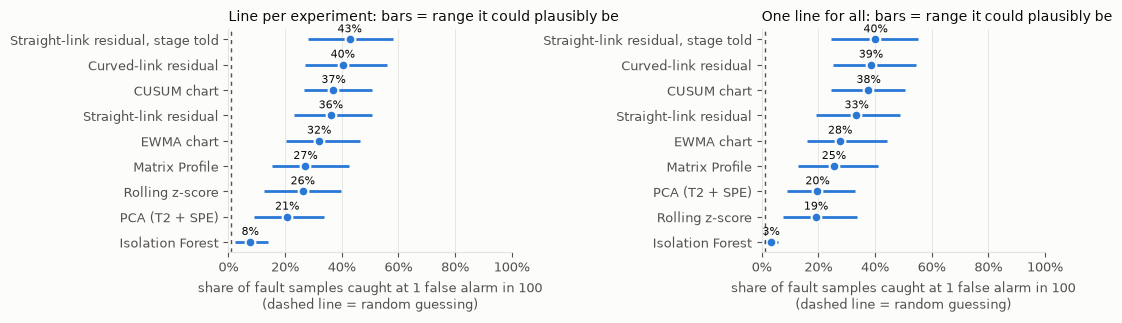

In [21]:
plots.pilot_overall({"each": each, "one": one},
                    titles={"each": "Line per experiment", "one": "One line for all"});

In [22]:
batch.check_table(each)

,experiment 29,experiment 31,experiment 33
detector,,,
Rolling z-score,0.008,0.003,0.022
EWMA chart,0.002,0.003,0.012
CUSUM chart,0.011,0.016,0
PCA (T2 + SPE),0.011,0.013,0.012
Isolation Forest,0.011,0.013,0.01
Matrix Profile,0,0,0.003
Straight-link residual,0.013,0.004,0.01
Curved-link residual,0.011,0.003,0.006
"Straight-link residual, stage told",0.013,0.004,0.009


**What this shows.**

- **Main version, line per experiment.** The straight-link detector told the step is first at 0.43 (0.28 to 0.58). Then come the curved-link detector at 0.40 (0.27 to 0.56), CUSUM at 0.37, the plain straight-link detector at 0.36 and EWMA at 0.32. Matrix Profile, the rolling z-score and PCA are at 0.21 to 0.27, and Isolation Forest at 0.08.
- **The lines carry over.** On the 20 normal check wafers, which no detector was fitted on and no line was set on, false alarms are 0.001 to 0.014: about the 1 in 100 the lines are set for. Split by experiment (last table), the worst is 0.022. This is the opposite of the Cranfield rig, where the line from a separate normal run gave 48 to 58% false alarms. Setting a line per experiment was decided in advance, because of that lesson.
- **One line for all three experiments** gives nearly the same order, a few points lower for most detectors. Its false alarms on check wafers are also near 0.01 overall, but uneven by experiment: CUSUM gives 0.05 on experiment 29's check wafers.

The ranges are wide (about ±15 points) because there are only 21 faulty wafers, and they differ a lot from each other.

## 14. Which detector is ahead?

Every pair of detectors, under the main line. A detector is "ahead" of another only if the gap is at least 12 points and its range does not include zero; otherwise it is a "tie". The second table picks out the two comparisons this task is about: the curved-link detector against the straight-link one, and the step-told straight-link detector against the plain one.

In [23]:
run.verdict_table(each)

,"Straight-link residual, stage told",Curved-link residual,CUSUM chart,Straight-link residual,EWMA chart,Matrix Profile,Rolling z-score,PCA (T2 + SPE),Isolation Forest
row against column,,,,,,,,,
"Straight-link residual, stage told",,tie,tie,tie,tie,ahead,ahead,ahead,ahead
Curved-link residual,tie,,tie,tie,tie,ahead,ahead,ahead,ahead
CUSUM chart,tie,tie,,tie,tie,tie,tie,ahead,ahead
Straight-link residual,tie,tie,tie,,tie,tie,tie,ahead,ahead
EWMA chart,tie,tie,tie,tie,,tie,tie,tie,ahead
Matrix Profile,behind,behind,tie,tie,tie,,tie,tie,ahead
Rolling z-score,behind,behind,tie,tie,tie,tie,,tie,ahead
PCA (T2 + SPE),behind,behind,behind,behind,tie,tie,tie,,ahead
Isolation Forest,behind,behind,behind,behind,behind,behind,behind,behind,


In [24]:
pd.concat({"curved-link against": run.gap_table(each, "Curved-link residual", ["Straight-link residual"]),
           "stage-told straight-link against": run.gap_table(each, "Straight-link residual, stage told", ["Straight-link residual"])})

,,gap,low,high,verdict
,Curved-link residual against,,,,
curved-link against,Straight-link residual,0.042,0.004,0.095,tie
stage-told straight-link against,Straight-link residual,0.067,0.001,0.125,tie


**What this shows.**

- The top five (step-told straight-link, curved-link, CUSUM, plain straight-link, EWMA) are all **tied** with each other.
- **Curved-link against straight-link: +4.2 points, range +0.4 to +9.5.** The range is just above zero, so the curved-link detector is slightly ahead on these wafers. But the gap is far below the 12-point margin, so by the project's rule it is **a tie**.
- **Step-told straight-link against plain straight-link: +6.7 points (+0.1 to +12.5): a tie** by the same rule.
- The curved-link and step-told detectors are ahead of Matrix Profile, the rolling z-score, PCA and Isolation Forest.

## 15. Kinds of fault

The first table: every detector's catch rate on each kind of fault (main line). The second groups the detectors into families, as in earlier notebooks: level checks (rolling z-score, EWMA, CUSUM), straight links (PCA, straight-link residual), curved links, and shape in time (Matrix Profile). "Sensors moved" is how many sensors, each judged on its own, are out of range for most of the wafer. The label: *single sensor* or *many sensors* if level checks catch at least half; *hidden from level checks* if they do not but another family does; *hard for all* if nothing catches half.

In [25]:
display(run.fault_table(each))
etch.kinds(each)

,"Straight-link residual, stage told",Curved-link residual,CUSUM chart,Straight-link residual,EWMA chart,Matrix Profile,Rolling z-score,PCA (T2 + SPE),Isolation Forest
kind of fault,,,,,,,,,
BCl3 flow,0.67,0.62,0.48,0.6,0.52,0.54,0.46,0.37,0.03
chamber pressure,0.97,0.78,0.73,0.72,0.83,0.75,0.74,0.67,0.3
chlorine flow,0.2,0.07,0.36,0.01,0.1,0,0.03,0.02,0.01
helium chuck,0.05,0.08,0,0.05,0,0.52,0,0.01,0.02
radio-frequency power,0.17,0.21,0.08,0.21,0.05,0.09,0.06,0.03,0.02
top coil power,0.29,0.39,0.33,0.33,0.22,0.04,0.14,0.07,0.01


,level checks,straight links,curved links,shape in time,sensors moved,kind
kind of fault,,,,,,
top coil power,0.333,0.329,0.388,0.038,0.3,hard for all
radio-frequency power,0.079,0.208,0.21,0.09,0,hard for all
chamber pressure,0.829,0.723,0.785,0.749,2.2,single sensor
BCl3 flow,0.525,0.604,0.62,0.538,0.7,single sensor
chlorine flow,0.355,0.016,0.072,0,0,hard for all
helium chuck,0,0.051,0.081,0.515,0,hidden from level checks


**What this shows.**

- **Chamber pressure faults: caught by everything** (0.67 to 0.97; the step-told straight-link detector 0.97). The pressure itself was shifted back to look normal, but the valve that holds it has to move a long way, and a level check sees that. Label: *single sensor*.
- **BCl3 flow: about half caught** (0.46 to 0.67). *Single sensor*.
- **Top coil power and RF power: hard for all.** The best is the curved-link detector, at 0.39 for top coil power and 0.21 for RF power. These are the faults the authors designed to be hidden: the power reading looks normal, and the effect on the other sensors is small.
- **Chlorine flow: hard for all.** CUSUM is best at 0.36; the link detectors catch almost none.
- **Helium chuck (one wafer): hidden from level checks.** Only Matrix Profile catches half of it.

For the two power faults, the link detectors (straight or curved) do better than the level checks. That is what the authors expected: the faulty setting looks normal, but its link to the other sensors is wrong.

## 16. Summary

**Against the "yes" rule.** The headline (all wafers pooled, same moment) is a curved share of **+8.1 points, range +7.9 to +8.4: the whole range is above +3 points.** With the step told it is **+7.2 (+7.0 to +7.4)**, far above +1, so by rule 5 it is not step-to-step level shifts. This is the first "yes" in the project. Inside each step the measure is also above +3: +8.3 in step 4, +5.4 in step 5.

**Against the deep-model test-bed condition** (clears +3 **and** the curved-link detector beats the straight-link by the margin): **not met.** The curved-link detector catches 0.40 of faulty readings against 0.36 for the straight-link one. That gap of +4.2 points (+0.4 to +9.5) is a tie under the 12-point margin.

**What the "yes" is made of.**

1. **Not smooth curves.** All seven sensors over 10 points are separate patches (phases of the wafer, experiments, start-up swings) or coarse readings flipping between values (section 11).
2. **Not just level shifts either.** Told the experiment, the step and experiment, or the tenth of the step, the straight model still leaves +4.6 to +6.0 points. Inside each experiment the measure is +5.6 to +7.3 (section 10). These checks were added after seeing the headline.
3. **Partly timing.** Offering the sensors' last 1 to 10 seconds brings it down to +3.1 (section 6), and the start of each wafer holds much of the gain for pressure and the top coil impedance (section 10).

**Detectors.** The best five are tied: step-told straight-link 0.43, curved-link 0.40, CUSUM 0.37, straight-link 0.36, EWMA 0.32 (line per experiment, ranges about ±15 points). The lines set per experiment carry over to unseen normal wafers (false alarms 0.001 to 0.014). The two "hidden" power faults are where link detectors help most, but they are still mostly missed.

**Choices, and when they were made.**

- Before measuring: the columns; the stub wafer left out; the rounds; the step as stage; the lags; the detector roles and the line per experiment; labelling every reading of a faulty wafer as faulty (from the authors' paper and the fault table, before any detector ran).
- After seeing results, for explanation only: section 10 (experiment and tenth-of-step checks, where in the wafer the gain is, traces) and the plot coloured by experiment in section 11. No threshold or model setting was chosen after seeing results.
- The outlier rule was applied and not triggered.